import pandas as pd

df = pd.read_csv("/ecommerce_customer_behavior_dataset.csv")

df.head()



In [1]:

import pandas as pd
import matplotlib.pyplot as plt

# Upload the dataset if it is missing
from google.colab import files
uploaded = files.upload()

# Load the uploaded CSV
df = pd.read_csv("ecommerce_customer_behavior_dataset.csv")

# Convert dates
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Confirm everything is ready
print("Dataset Shape:", df.shape)
print("Invalid Dates:", df["Date"].isnull().sum())

display(df.head())


Saving ecommerce_customer_behavior_dataset.csv to ecommerce_customer_behavior_dataset.csv
Dataset Shape: (5000, 18)
Invalid Dates: 0


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,Mobile,8,10,False,1,4
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,Cash on Delivery,Desktop,21,10,True,7,4


In [ ]:
import pandas as pd

df = pd.read_csv("/ecommerce_customer_behavior_dataset.csv")

df.head()


FileNotFoundError: [Errno 2] No such file or directory: '/ecommerce_customer_behavior_dataset.csv'

In [ ]:

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display the names of all columns
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()


NameError: name 'df' is not defined

In [ ]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())


Missing Values:
Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64

Duplicate Rows:
0

Descriptive Statistics:


,Age,Unit_Price,Quantity,Discount_Amount,Total_Amount,Session_Duration_Minutes,Pages_Viewed,Delivery_Time_Days,Customer_Rating
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.00000,5000.000000,5000.000000
mean,35.032600,455.834120,2.220000,24.852804,983.108914,14.57340,8.98420,6.497000,3.902800
std,11.080546,712.477209,1.398711,88.385124,1898.978528,8.66575,2.80434,3.464966,1.128542
min,18.000000,5.180000,1.000000,0.000000,7.870000,1.00000,1.00000,1.000000,1.000000
25%,27.000000,76.587500,1.000000,0.000000,122.517500,8.00000,7.00000,4.000000,3.000000
50%,35.000000,182.950000,2.000000,0.000000,337.910000,13.00000,9.00000,6.000000,4.000000
75%,42.000000,513.930000,3.000000,8.760000,979.695000,19.00000,11.00000,8.000000,5.000000
max,75.000000,7159.450000,5.000000,1525.550000,22023.900000,73.00000,24.00000,25.000000,5.000000


In [ ]:

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check the updated data type
print("Date Data Type:", df["Date"].dtype)

# Check for invalid dates
print("Invalid Dates:", df["Date"].isnull().sum())

# Check the date range
print("Earliest Date:", df["Date"].min())
print("Latest Date:", df["Date"].max())


Date Data Type: datetime64[ns]
Invalid Dates: 0
Earliest Date: 2023-01-01 00:00:00
Latest Date: 2024-03-26 00:00:00


In [ ]:

# Group transactions by month and calculate total revenue
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Total_Amount"]
    .sum()
    .reset_index()
)

# Rename columns for readability
monthly_sales.columns = ["Month", "Revenue"]

# Display monthly sales
display(monthly_sales)


,Month,Revenue
0,2023-01,286694.32
1,2023-02,338784.92
2,2023-03,321716.01
3,2023-04,257332.58
4,2023-05,351902.03
5,2023-06,324356.96
6,2023-07,346618.03
7,2023-08,391505.89
8,2023-09,262602.86
9,2023-10,352286.61


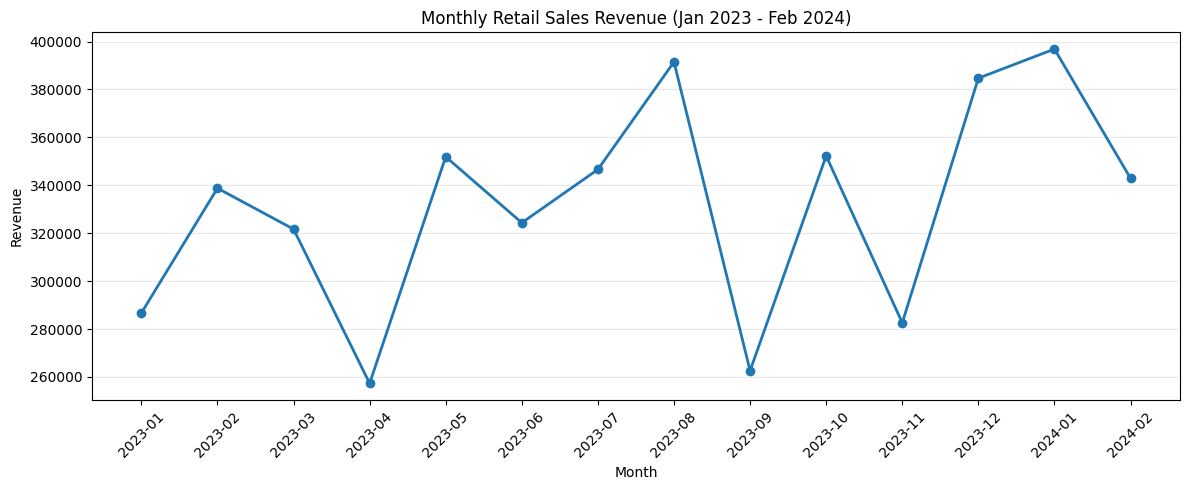

In [ ]:

import matplotlib.pyplot as plt

# Exclude the incomplete final month
complete_months = monthly_sales[
    monthly_sales["Month"] < pd.Period("2024-03", freq="M")
].copy()

# Convert months to text for chart labels
complete_months["Month_Label"] = complete_months["Month"].astype(str)

# Create the chart
plt.figure(figsize=(12, 5))

plt.plot(
    complete_months["Month_Label"],
    complete_months["Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Revenue (Jan 2023 - Feb 2024)")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


In [ ]:

# Keep only complete quarters (2023)
quarterly_data = df[
    (df["Date"] >= "2023-01-01") &
    (df["Date"] < "2024-01-01")
].copy()

# Calculate total revenue for each quarter
quarterly_sales = (
    quarterly_data.groupby(
        quarterly_data["Date"].dt.to_period("Q")
    )["Total_Amount"]
    .sum()
    .reset_index()
)

quarterly_sales.columns = ["Quarter", "Revenue"]

display(quarterly_sales)


,Quarter,Revenue
0,2023Q1,947195.25
1,2023Q2,933591.57
2,2023Q3,1000726.78
3,2023Q4,1019610.23


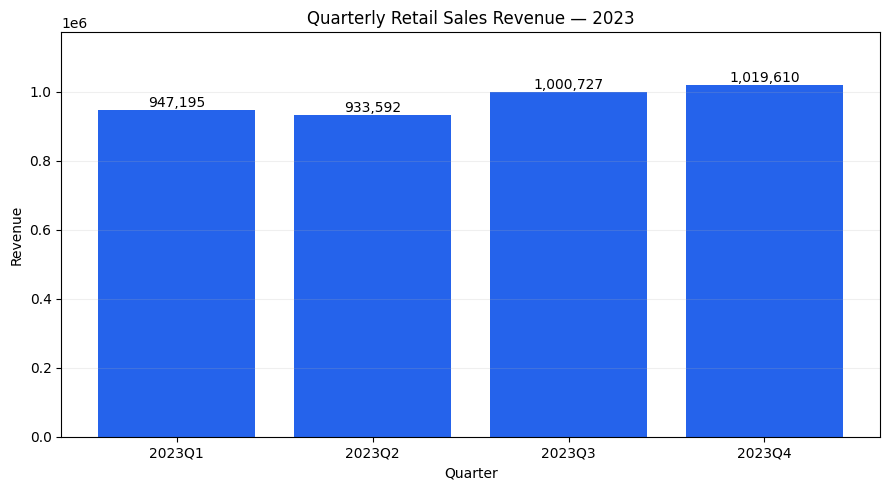

In [ ]:

# Convert quarters into readable labels
quarterly_sales["Quarter_Label"] = quarterly_sales["Quarter"].astype(str)

# Create a quarterly revenue bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    quarterly_sales["Quarter_Label"],
    quarterly_sales["Revenue"],
    color="#2563EB"
)

# Add revenue labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.title("Quarterly Retail Sales Revenue — 2023")
plt.xlabel("Quarter")
plt.ylabel("Revenue")
plt.ylim(0, quarterly_sales["Revenue"].max() * 1.15)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:
# STEP 10: Product Category Performance Analysis

category_sales = (
    df.groupby("Product_Category")
    .agg(
        Total_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

# Round revenue to two decimal places
category_sales["Total_Revenue"] = (
    category_sales["Total_Revenue"].round(2)
)

display(category_sales)

NameError: name 'df' is not defined

In [2]:

# Calculate revenue, orders and units sold by category
category_sales = (
    df.groupby("Product_Category")
    .agg(
        Total_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

# Round revenue for easier reading
category_sales["Total_Revenue"] = category_sales["Total_Revenue"].round(2)

display(category_sales)


,Product_Category,Total_Revenue,Total_Orders,Units_Sold
2,Electronics,2328806.81,624,1379
5,Home & Garden,908348.86,621,1353
6,Sports,754563.56,667,1519
3,Fashion,375214.93,622,1411
7,Toys,223142.48,610,1368
0,Beauty,156584.74,621,1424
4,Food,96138.67,619,1355
1,Books,72744.52,616,1291


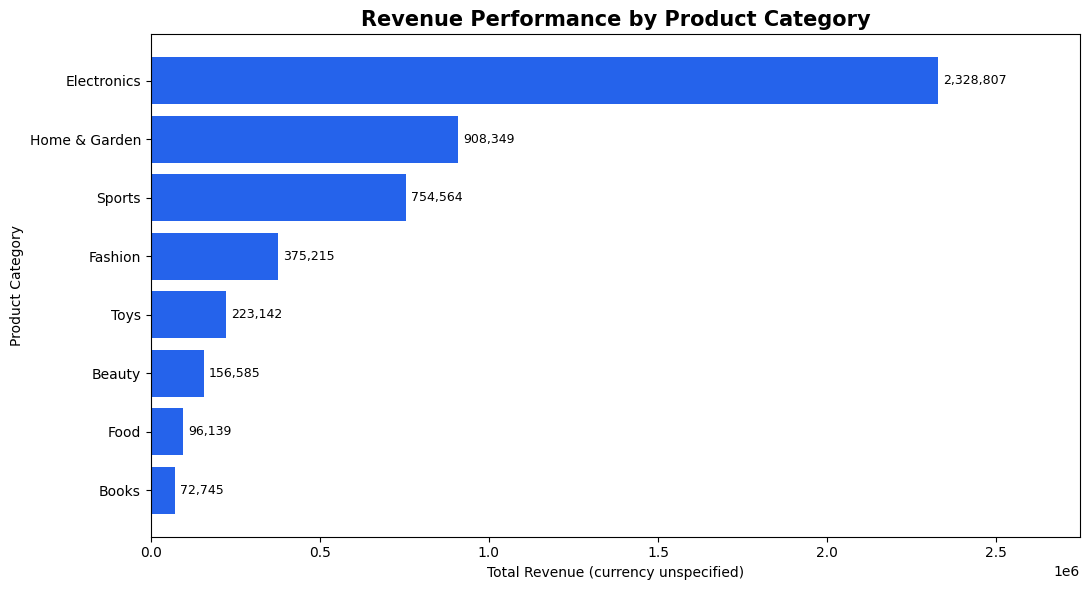

In [3]:

import matplotlib.pyplot as plt

# Arrange categories from lowest to highest revenue
chart_data = category_sales.sort_values("Total_Revenue")

plt.figure(figsize=(11, 6))

bars = plt.barh(
    chart_data["Product_Category"],
    chart_data["Total_Revenue"],
    color="#2563EB"
)

plt.title("Revenue Performance by Product Category",
          fontsize=15, fontweight="bold")

plt.xlabel("Total Revenue (currency unspecified)")
plt.ylabel("Product Category")

# Display revenue values beside each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 15000,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, chart_data["Total_Revenue"].max() * 1.18)
plt.tight_layout()
plt.show()


In [4]:

# STEP 11: Customer Demographics Analysis

# Revenue and orders by gender
gender_sales = (
    df.groupby("Gender")
    .agg(
        Total_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

gender_sales["Total_Revenue"] = gender_sales["Total_Revenue"].round(2)

print("Sales Performance by Gender:")
display(gender_sales)

# Create customer age groups
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 24, 34, 44, 54, float("inf")],
    labels=["18-24", "25-34", "35-44", "45-54", "55+"]
)

# Revenue and orders by age group
age_sales = (
    df.groupby("Age_Group", observed=True)
    .agg(
        Total_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

age_sales["Total_Revenue"] = age_sales["Total_Revenue"].round(2)

print("\nSales Performance by Age Group:")
display(age_sales)


Sales Performance by Gender:


,Gender,Total_Revenue,Total_Orders
0,Female,2474009.26,2492
1,Male,2381028.70,2435
2,Other,60506.61,73



Sales Performance by Age Group:


,Age_Group,Total_Revenue,Total_Orders
0,18-24,1005207.55,998
1,25-34,1436981.67,1476
2,35-44,1483006.07,1521
3,45-54,747805.60,769
4,55+,242543.68,236


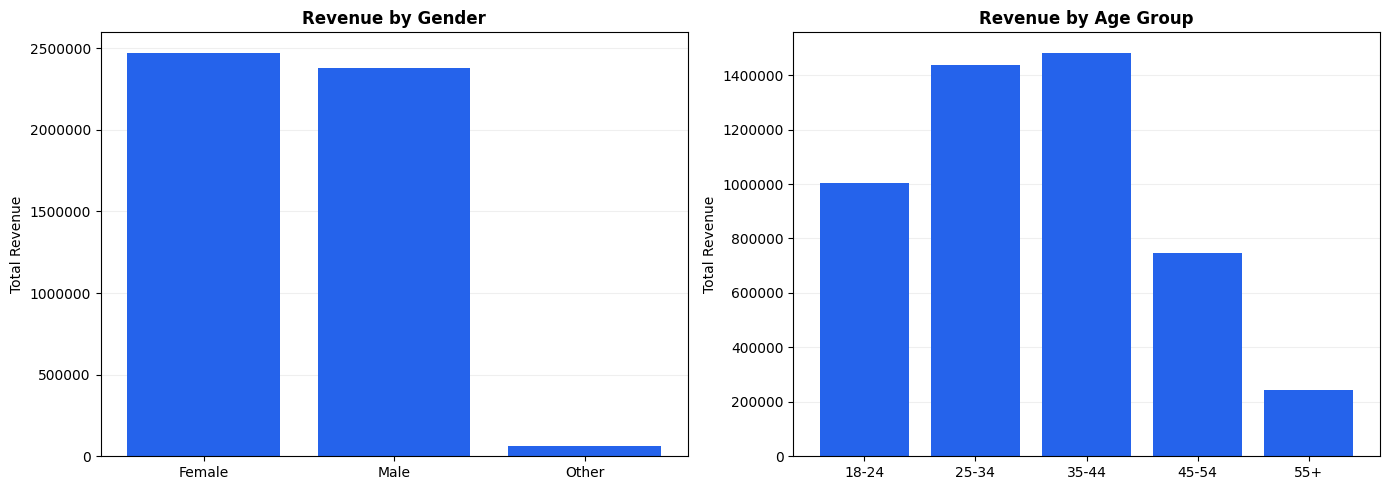

In [5]:

# STEP 12: Customer Demographics Visualisation

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by Gender
axes[0].bar(
    gender_sales["Gender"],
    gender_sales["Total_Revenue"],
    color="#2563EB"
)

axes[0].set_title("Revenue by Gender", fontweight="bold")
axes[0].set_ylabel("Total Revenue")

# Revenue by Age Group
axes[1].bar(
    age_sales["Age_Group"].astype(str),
    age_sales["Total_Revenue"],
    color="#2563EB"
)

axes[1].set_title("Revenue by Age Group", fontweight="bold")
axes[1].set_ylabel("Total Revenue")

# Format both charts
for ax in axes:
    ax.ticklabel_format(axis="y", style="plain")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [6]:

# STEP 13: Customer Purchasing Behaviour Analysis

# Returning vs New Customers
df["Customer_Type"] = df["Is_Returning_Customer"].map({
    True: "Returning",
    False: "New"
})

customer_behavior = (
    df.groupby("Customer_Type")
    .agg(
        Total_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Average_Order_Value=("Total_Amount", "mean")
    )
    .round(2)
    .reset_index()
)

print("Returning vs New Customers:")
display(customer_behavior)

# Payment Method Analysis
payment_analysis = (
    df.groupby("Payment_Method")
    .agg(
        Total_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
    .reset_index()
)

print("\nSales by Payment Method:")
display(payment_analysis)

# Device Type Analysis
device_analysis = (
    df.groupby("Device_Type")
    .agg(
        Total_Revenue=("Total_Amount", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
    .reset_index()
)

print("\nSales by Device Type:")
display(device_analysis)


Returning vs New Customers:


,Customer_Type,Total_Revenue,Total_Orders,Average_Order_Value
0,New,1967523.73,2010,978.87
1,Returning,2948020.84,2990,985.96



Sales by Payment Method:


,Payment_Method,Total_Revenue,Total_Orders
0,Credit Card,1916670.38,2012
1,Debit Card,1250502.73,1265
2,Digital Wallet,963056.98,965
3,Bank Transfer,550872.17,510
4,Cash on Delivery,234442.31,248



Sales by Device Type:


,Device_Type,Total_Revenue,Total_Orders
0,Mobile,2810468.64,2795
1,Desktop,1650103.78,1711
2,Tablet,454972.15,494


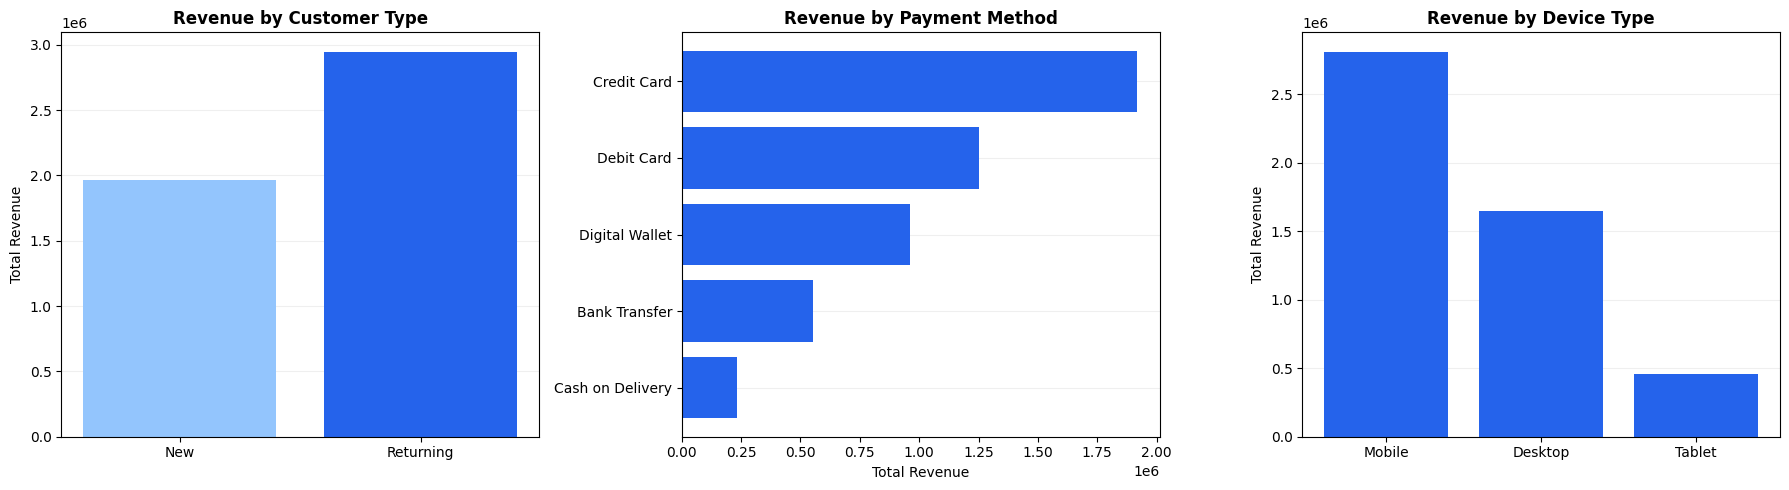

In [7]:

# STEP 14: Customer Purchasing Behaviour Charts

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Returning vs New Customers
axes[0].bar(
    customer_behavior["Customer_Type"],
    customer_behavior["Total_Revenue"],
    color=["#93C5FD", "#2563EB"]
)
axes[0].set_title("Revenue by Customer Type", fontweight="bold")
axes[0].set_ylabel("Total Revenue")

# Chart 2: Revenue by Payment Method
axes[1].barh(
    payment_analysis["Payment_Method"],
    payment_analysis["Total_Revenue"],
    color="#2563EB"
)
axes[1].invert_yaxis()
axes[1].set_title("Revenue by Payment Method", fontweight="bold")
axes[1].set_xlabel("Total Revenue")

# Chart 3: Revenue by Device Type
axes[2].bar(
    device_analysis["Device_Type"],
    device_analysis["Total_Revenue"],
    color="#2563EB"
)
axes[2].set_title("Revenue by Device Type", fontweight="bold")
axes[2].set_ylabel("Total Revenue")

# Improve chart readability
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Customer Engagement Correlation Matrix:


,Session_Duration_Minutes,Pages_Viewed,Delivery_Time_Days,Customer_Rating,Total_Amount
Session_Duration_Minutes,1.000,0.024,0.015,0.026,-0.004
Pages_Viewed,0.024,1.000,0.002,0.007,-0.012
Delivery_Time_Days,0.015,0.002,1.000,-0.010,-0.006
Customer_Rating,0.026,0.007,-0.010,1.000,0.006
Total_Amount,-0.004,-0.012,-0.006,0.006,1.000


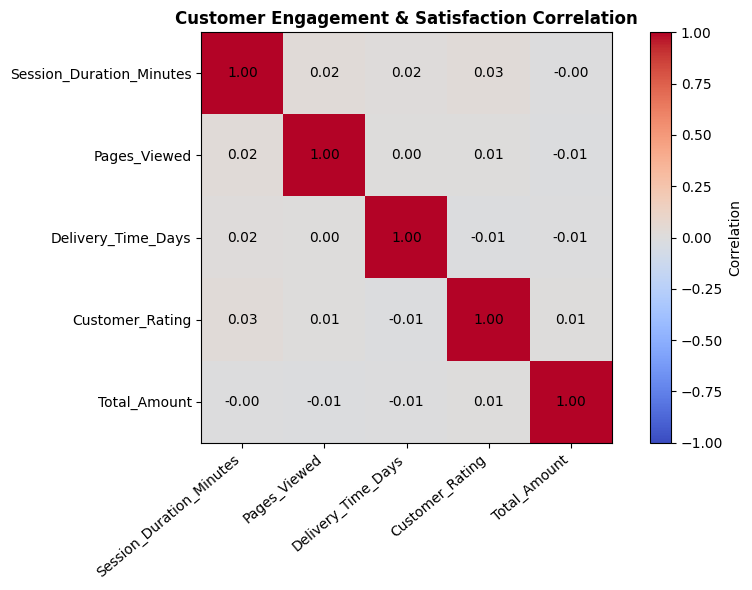

In [8]:

# STEP 15: Customer Engagement & Satisfaction Analysis

import matplotlib.pyplot as plt

# Select numerical variables for analysis
engagement_columns = [
    "Session_Duration_Minutes",
    "Pages_Viewed",
    "Delivery_Time_Days",
    "Customer_Rating",
    "Total_Amount"
]

# Calculate correlations
correlation_matrix = df[engagement_columns].corr()

print("Customer Engagement Correlation Matrix:")
display(correlation_matrix.round(3))

# Create correlation heatmap
fig, ax = plt.subplots(figsize=(9, 6))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(engagement_columns)))
ax.set_yticks(range(len(engagement_columns)))

ax.set_xticklabels(engagement_columns, rotation=40, ha="right")
ax.set_yticklabels(engagement_columns)

# Display correlation values inside the heatmap
for i in range(len(engagement_columns)):
    for j in range(len(engagement_columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

plt.colorbar(heatmap, ax=ax, label="Correlation")
plt.title("Customer Engagement & Satisfaction Correlation",
          fontweight="bold")

plt.tight_layout()
plt.show()


## Step 16: Key Findings and Business Recommendations

### Key Findings

1. **Product Performance:** Electronics generated approximately 2.33 million in revenue, making it the highest-performing product category. Books generated approximately 72.7 thousand, the lowest among the categories analysed.

2. **Customer Retention:** Returning-customer transactions contributed approximately 2.95 million in revenue, compared with 1.97 million from new-customer transactions.

3. **Customer Demographics:** Customers aged 35–44 generated the highest revenue, followed closely by customers aged 25–34.

4. **Payment Preferences:** Credit cards generated the highest transaction revenue, followed by debit cards and digital wallets.

5. **Device Performance:** Mobile devices contributed approximately 2.81 million in revenue, exceeding desktop and tablet purchases.

6. **Customer Engagement:** Correlation analysis revealed no meaningful linear relationship between browsing duration, pages viewed, delivery time, customer ratings and purchase amounts.

### Business Recommendations

- **Prioritise high-performing categories:** Maintain strong product availability in Electronics while investigating opportunities to improve lower-performing categories.
- **Strengthen customer retention:** Develop loyalty initiatives and targeted offers for returning customers.
- **Optimise mobile shopping:** Improve mobile website usability and checkout performance because mobile transactions account for the largest revenue share.
- **Improve payment convenience:** Maintain reliable credit-card and debit-card payment options while supporting digital wallets.
- **Test engagement improvements:** Use controlled experiments to determine whether changes to browsing experience or delivery operations improve sales and satisfaction.

### Conclusion

This exploratory data analysis identified important patterns in retail revenue, customer demographics, purchasing behaviour and product performance. The findings provide a foundation for data-informed business decisions, while the correlation results highlight the importance of testing assumptions rather than relying on intuition.

*Note: Monetary values are reported in unspecified currency units because the dataset does not identify a currency.*